# 定义损失函数

In [1]:
import torch
from torch.optim import SGD, RMSprop
import numpy as np
import matplotlib.pyplot as plt
# 定义损失函数：传入参数向量（二元）
def loss_fn(w):
    return 0.05 * w[0]**2 + w[1] ** 2

# 定义函数，实现梯度下降法

In [2]:
# 定义函数，实现梯度下降法流程，传入 初始参数、优化器、训练迭代次数
def gradient_descent(w, optimizer, epochs):
    # 用列表保存参数点坐标
    w0_list = []
    w1_list = []
    for i in range(epochs):
        w0_list.append(w[0].item())
        w1_list.append(w[1].item())
        # 1. 前向传播、计算损失
        loss = loss_fn(w)
        # 2. 反向传播
        loss.backward()
        # 3. 更新参数
        optimizer.step()
        # 4. 梯度清零
        optimizer.zero_grad()
    return w0_list, w1_list


#定义参数

In [3]:
# 定义训练超参数
lr = 0.1
n_iters = 500

# 定义初始参数
start_w=[-7.0, 2]

# 对比不同的优化器
##  1. SGD

In [4]:

sgd_w = torch.tensor(start_w, requires_grad=True)
optimizer = SGD([sgd_w], lr=lr)
sgd_w0_list, sgd_w1_list = gradient_descent(sgd_w, optimizer, n_iters)

# 2. RMSProp

In [5]:

rms_w = torch.tensor(start_w, requires_grad=True)
optimizer = RMSprop([rms_w], lr=lr)
rms_w0_list, rms_w1_list = gradient_descent(rms_w, optimizer, n_iters)


# 对比图

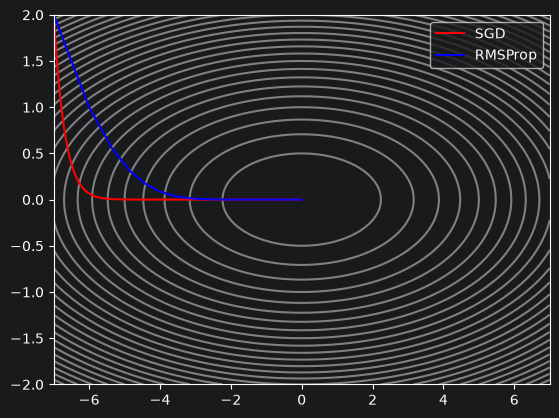

In [6]:

w0, w1 = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
loss = loss_fn([w0, w1])
plt.contour(w0, w1, loss, colors='gray', levels=30)
plt.plot(sgd_w0_list, sgd_w1_list, color='r')
plt.plot(rms_w0_list, rms_w1_list, color='b')
plt.legend(['SGD', 'RMSProp'])
plt.show()

# 总结
它并非将过去所有梯度一视同仁的相加，而是逐渐遗忘过去的梯度，采用指数移动加权平均，呈指数地减小过去梯度的尺度。

缺点：
- 当梯度为0时，会直接停止更新
